<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/naive_bayes_sms_spam_lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 4
## Наївний байєсівський класифікатор в системах машинного навчання

**Мета:** створити спам-фільтр на основі наївного байєсівського класифікатора, оцінити його якість та дослідити проблему нульової ймовірності і спосіб її усунення (згладжування Лапласа).

**Завдання:** створити спам-фільтр на основі наївного байєсівського класифікатора на даних датасету з підбірки Kaggle (*spam*); дослідити проблему нульової ймовірності для алгоритму Байєса.

**Датасет:** SMS Spam Collection ([Kaggle: uciml/sms-spam-collection-dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)) — 5 572 англомовні SMS, позначені як `ham` (звичайне повідомлення) або `spam`.

**Чому цей датасет:** з трьох розглянутих кандидатів (SMS Spam Collection, Spam Email Dataset, Spam Mails Dataset) він найкраще підходить до теми. Це класичний бенчмарк для наївного Байєса; повідомлення короткі (≈ 14 слів), тому проблему нульової ймовірності можна показати на конкретному прикладі; дисбаланс класів (≈ 87% / 13%) вимагає оцінювати фільтр за precision та recall, а не лише за accuracy.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних (очищення, розділення на train/test, векторизація тексту)
4. Реалізація наївного байєсівського класифікатора
5. Базовий спам-фільтр
6. Дослідження проблеми нульової ймовірності: наочний приклад, масштаб проблеми, класифікатор без згладжування, згладжування Лапласа (вплив `alpha`), вплив розміру навчальної вибірки
7. Фінальний фільтр та оцінка якості
8. Перевірка фільтра на нових повідомленнях
9. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл береться з поточної папки; якщо його там немає — завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження CSV.

In [2]:
FILE_NAME = "spam.csv"

def find_dataset():
    if os.path.exists(FILE_NAME):
        return FILE_NAME
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        folder = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")
        csv_files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        csv_files.sort(key=lambda p: os.path.basename(p) != FILE_NAME)  # потрібний файл — першим
        if csv_files:
            return csv_files[0]
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print(f"Завантажте файл {FILE_NAME} вручну:")
    return next(iter(files.upload()))

raw = pd.read_csv(find_dataset(), encoding="latin-1")   # файл не в UTF-8
print("Датасет завантажено:", raw.shape)

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
Датасет завантажено: (5572, 5)


## 2. Первинний аналіз даних
Дивимось на структуру таблиці, пропуски, дублікати, розподіл класів та довжину повідомлень.

In [3]:
print("Колонки:", raw.columns.tolist())
print("\nЧастка пропусків за колонками:")
print(raw.isna().mean().round(4).to_string())
print("\nДублікатів повідомлень:", int(raw.duplicated(subset="v2").sum()))

raw[["v1", "v2"]].sample(6, random_state=RANDOM_STATE)

Колонки: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Частка пропусків за колонками:
v1            0.0000
v2            0.0000
Unnamed: 2    0.9910
Unnamed: 3    0.9978
Unnamed: 4    0.9989

Дублікатів повідомлень: 403


,v1,v2
3245,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
944,ham,I sent my scores to sophas and i had to do sec...
1044,spam,We know someone who you know that fancies you....
2484,ham,Only if you promise your getting out as SOON a...
812,spam,Congratulations ur awarded either å£500 of CD ...
2973,ham,"I'll text carlos and let you know, hang on"


Середня довжина повідомлення (слів):
v1
ham     14.2
spam    23.9


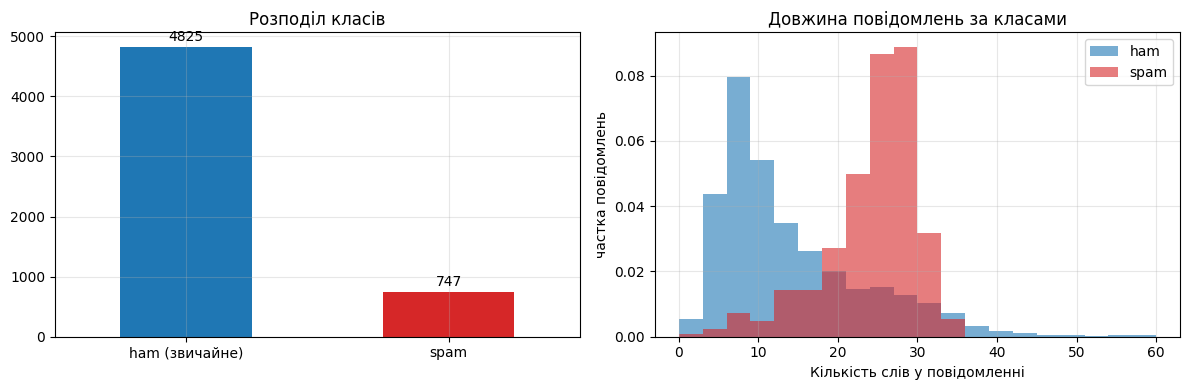

In [4]:
n_words = raw["v2"].str.split().str.len()
print("Середня довжина повідомлення (слів):")
print(n_words.groupby(raw["v1"]).mean().round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
raw["v1"].map({"ham": "ham (звичайне)", "spam": "spam"}).value_counts().plot.bar(ax=ax[0], rot=0, color=["tab:blue", "tab:red"])
ax[0].set_title("Розподіл класів"); ax[0].set_xlabel(""); ax[0].bar_label(ax[0].containers[0], padding=2)

for lab, color, name in [("ham", "tab:blue", "ham"), ("spam", "tab:red", "spam")]:
    ax[1].hist(n_words[raw["v1"] == lab], bins=range(0, 63, 3), alpha=0.6, color=color, label=name, density=True)
ax[1].set_xlabel("Кількість слів у повідомленні"); ax[1].set_ylabel("частка повідомлень")
ax[1].set_title("Довжина повідомлень за класами"); ax[1].legend()
plt.tight_layout(); plt.show()

**Висновок.** Датасет містить 5 572 SMS у двох змістовних колонках (мітка `v1` і текст `v2`); три колонки `Unnamed: 2–4` майже порожні (заповнені менш ніж на 1%) і є службовим сміттям, тому їх не використовуємо. Класи незбалансовані: 4 825 ham проти 747 spam (≈ 13% спаму). Спам помітно довший: у середньому ≈ 24 слова проти ≈ 14. Також є 403 дублікати текстів (≈ 7%), які потрібно прибрати до розділення на train/test.

## 3. Підготовка даних
Етапи: залишаємо лише мітку та текст → видаляємо дублікати (інакше однакові повідомлення потраплять і в train, і в test) → розділяємо на навчальну та тестову вибірки (80/20 зі збереженням пропорцій класів) → перетворюємо текст у вектори частот слів (`CountVectorizer`, модель «мішок слів»). Словник будується лише за навчальною вибіркою.

In [5]:
data = (raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})
        .drop_duplicates(subset="text").reset_index(drop=True))
data["y"] = (data["label"] == "spam").astype(int)      # 1 — спам, 0 — ham

X_train, X_test, y_train, y_test = train_test_split(
    data["text"], data["y"], test_size=0.2, stratify=data["y"], random_state=RANDOM_STATE)

vectorizer = CountVectorizer()          # нижній регістр, токени з ≥ 2 символів
A_train = vectorizer.fit_transform(X_train)
A_test = vectorizer.transform(X_test)
vocab = np.array(vectorizer.get_feature_names_out())
analyzer = vectorizer.build_analyzer()

print(f"Після видалення дублікатів: {len(data)} повідомлень, частка спаму {data['y'].mean():.3f}")
print(f"Базовий рівень (завжди прогнозувати ham): accuracy = {1 - data['y'].mean():.4f}")
print(f"Навчальна вибірка: {len(X_train)}, тестова: {len(X_test)}")
print(f"Розмір словника (за навчальною вибіркою): {len(vocab)} слів")

Після видалення дублікатів: 5169 повідомлень, частка спаму 0.126
Базовий рівень (завжди прогнозувати ham): accuracy = 0.8737
Навчальна вибірка: 4135, тестова: 1034
Розмір словника (за навчальною вибіркою): 7591 слів


In [6]:
def metrics(y_true, y_pred):
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),   # частка справжнього спаму серед позначеного як спам
            "recall":    recall_score(y_true, y_pred),                       # частка виявленого спаму
            "f1":        f1_score(y_true, y_pred, zero_division=0)}

**Висновок.** Після видалення дублікатів залишилось 5 169 повідомлень (спаму ≈ 12,6%). Тривіальний фільтр «усе — ham» мав би accuracy 0,874, тож ця метрика не дає повної картини: для спам-фільтра головні precision та recall для класу spam. Словник навчальної вибірки — 7 591 слово.

## 4. Реалізація наївного байєсівського класифікатора
Спочатку реалізуємо алгоритм «вручну» за формулами з методички, щоб бачити, де саме виникає нульова ймовірність. Для повідомлення зі словами $x_1,\dots,x_m$ за теоремою Байєса і припущенням про незалежність слів:

$$P(c \mid x) \;\propto\; P(c)\prod_{i=1}^{m} P(x_i \mid c), \qquad P(w \mid c)=\frac{n_{w,c}+\alpha}{N_c+\alpha\,|V|},$$

де $n_{w,c}$ — скільки разів слово $w$ зустрілось у класі $c$, $N_c$ — загальна кількість слів класу $c$, $|V|$ — розмір словника, $\alpha$ — параметр згладжування (**$\alpha=1$ — згладжування Лапласа**, $\alpha=0$ — без згладжування). Щоб не отримувати занадто малих чисел (антипереповнення), множення замінюємо додаванням логарифмів.

In [7]:
class NaiveBayesManual:
    """Мультиноміальний наївний Байєс зі згладжуванням alpha. alpha=0 — без згладжування."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.log_prior_ = np.log([np.mean(y == c) for c in self.classes_])
        self.counts_ = np.vstack([np.asarray(X[y == c].sum(axis=0)).ravel() for c in self.classes_])
        total = self.counts_.sum(axis=1, keepdims=True)
        with np.errstate(divide="ignore"):                       # log(0) = -inf — це і є нульова ймовірність
            self.log_lik_ = np.log((self.counts_ + self.alpha) / (total + self.alpha * X.shape[1]))
        return self

    def joint_log_proba(self, X):
        """log P(c) + сума log P(w|c) за словами повідомлення."""
        return self.log_prior_ + X.dot(self.log_lik_.T)

    def undecided(self, X):
        """Повідомлення, для яких обидва класи мають нульову ймовірність."""
        return np.isinf(self.joint_log_proba(X)).all(axis=1)

    def predict(self, X):
        scores = self.joint_log_proba(X)
        pred = self.classes_[scores.argmax(axis=1)]
        pred[self.undecided(X)] = self.classes_[self.log_prior_.argmax()]   # без підстав — найчастіший клас
        return pred

Перевіряємо правильність власної реалізації, порівнявши її з `MultinomialNB` зі scikit-learn (при `alpha=1`).

In [8]:
nb_manual = NaiveBayesManual(alpha=1.0).fit(A_train, y_train.values)
nb_sklearn = MultinomialNB(alpha=1.0).fit(A_train, y_train)

same = (nb_manual.predict(A_test) == nb_sklearn.predict(A_test)).mean()
diff = np.abs(nb_manual.joint_log_proba(A_test) - nb_sklearn.predict_joint_log_proba(A_test)).max()
print(f"Збіг прогнозів зі sklearn: {same:.1%}")
print(f"Максимальна різниця log-ймовірностей: {diff:.2e}")

Збіг прогнозів зі sklearn: 100.0%
Максимальна різниця log-ймовірностей: 2.27e-13


**Висновок.** Власна реалізація повністю збігається зі `scikit-learn`: прогнози збігаються у 100% випадків, а log-ймовірності відрізняються лише на ≈ 10⁻¹³ (похибка обчислень). Отже, реалізація коректна, і її можна використовувати для дослідження нульових ймовірностей: вона явно працює з `alpha=0` і обробляє `log 0 = −∞`.

## 5. Базовий спам-фільтр
Класифікатор `MultinomialNB` зі згладжуванням Лапласа (`alpha=1`).

,базовий фільтр (alpha=1)
accuracy,0.9865
precision,0.9756
recall,0.9160
f1,0.9449


              precision    recall  f1-score   support

         ham     0.9879    0.9967    0.9923       903
        spam     0.9756    0.9160    0.9449       131

    accuracy                         0.9865      1034
   macro avg     0.9818    0.9564    0.9686      1034
weighted avg     0.9864    0.9865    0.9863      1034



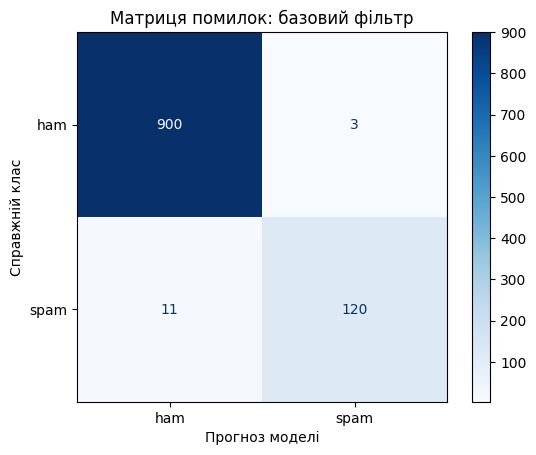

In [9]:
base_pred = nb_sklearn.predict(A_test)
display(pd.Series(metrics(y_test, base_pred)).round(4).to_frame("базовий фільтр (alpha=1)"))
print(classification_report(y_test, base_pred, target_names=["ham", "spam"], digits=4))

disp = ConfusionMatrixDisplay.from_predictions(y_test, base_pred, display_labels=["ham", "spam"], cmap="Blues", values_format="d")
disp.ax_.grid(False); disp.ax_.set_title("Матриця помилок: базовий фільтр")
disp.ax_.set(xlabel="Прогноз моделі", ylabel="Справжній клас")
plt.show()

**Висновок.** Базовий фільтр (`alpha=1`) має accuracy 0,987 і F1 для спаму 0,945 (precision 0,976, recall 0,916): із 903 звичайних повідомлень лише 3 помилково позначено як спам, але пропущено 11 зі 131 спам-повідомлень. Для порівняння, тривіальний фільтр має accuracy 0,874 при нульовому recall.

## 6. Дослідження проблеми нульової ймовірності
Якщо слово жодного разу не зустрілось у навчальних повідомленнях певного класу, то $P(w\mid c)=0$, а отже і весь добуток $P(c)\prod P(x_i\mid c)=0$ — **одне невідоме слово «обнуляє» клас**, незалежно від усіх інших слів повідомлення. Розглянемо, як це виглядає на практиці.

### 6.1. Наочний приклад
Будуємо дві моделі: без згладжування (`alpha=0`) та з Лапласом (`alpha=1`). Беремо з тесту справжній спам, який модель без згладжування пропускає через нульову ймовірність, а модель з Лапласом виявляє. Клітинки з нульовою ймовірністю виділено червоним.

In [10]:
nb0 = NaiveBayesManual(alpha=0).fit(A_train, y_train.values)   # без згладжування
nb1 = NaiveBayesManual(alpha=1).fit(A_train, y_train.values)   # згладжування Лапласа

s0 = nb0.joint_log_proba(A_test)
p0, p1 = nb0.predict(A_test), nb1.predict(A_test)
n_uniq = np.asarray((A_test > 0).sum(axis=1)).ravel()

# спам, у якого alpha=0 дає log P(spam)=-inf, а alpha=1 його виявляє; короткий, щоб таблиця була читабельною
cand = np.where((y_test.values == 1) & (p1 == 1) & np.isinf(s0[:, 1]) & (n_uniq >= 6) & (n_uniq <= 12))[0]
i = cand[np.argsort(n_uniq[cand], kind="stable")][0]
print("Повідомлення:", X_test.iloc[i], "\n")

cols = A_test[i].indices                                       # слова цього повідомлення, що є у словнику
table = pd.DataFrame({
    "слово": vocab[cols],
    "у spam, разів": nb0.counts_[1, cols].astype(int),
    "у ham, разів": nb0.counts_[0, cols].astype(int),
    "P(w|spam), alpha=0": np.exp(nb0.log_lik_[1, cols]),
    "P(w|spam), alpha=1": np.exp(nb1.log_lik_[1, cols]),
    "P(w|ham), alpha=0": np.exp(nb0.log_lik_[0, cols]),
    "P(w|ham), alpha=1": np.exp(nb1.log_lik_[0, cols]),
}).set_index("слово")
prob_cols = [c for c in table.columns if c.startswith("P(")]
display(table.style.format({c: "{:.2e}" for c in prob_cols})
        .map(lambda v: "background-color: #f8d7da" if v == 0 else "", subset=prob_cols))

def verdict(j, p):
    return "невизначено (обидва −∞) → за замовчуванням ham" if np.isinf(j).all() else ("spam" if p else "ham")

j0, j1 = nb0.joint_log_proba(A_test[i])[0], nb1.joint_log_proba(A_test[i])[0]
print(f"alpha=0: log P(ham, x) = {j0[0]:.2f},  log P(spam, x) = {j0[1]:.2f}  → прогноз: {verdict(j0, p0[i])}")
print(f"alpha=1: log P(ham, x) = {j1[0]:.2f},  log P(spam, x) = {j1[1]:.2f}  → прогноз: {verdict(j1, p1[i])}  (справжній клас: spam)")


Повідомлення: RECPT 1/3. You have ordered a Ringtone. Your order is being processed... 



,"у spam, разів","у ham, разів","P(w|spam), alpha=0","P(w|spam), alpha=1","P(w|ham), alpha=0","P(w|ham), alpha=1"
слово,,,,,,
being,3,27,2.47e-04,2.03e-04,5.82e-04,5.19e-04
have,91,323,7.50e-03,4.66e-03,6.96e-03,6.00e-03
is,119,507,9.81e-03,6.08e-03,1.09e-02,9.41e-03
order,12,5,9.89e-04,6.59e-04,1.08e-04,1.11e-04
ordered,1,1,8.24e-05,1.01e-04,2.16e-05,3.70e-05
processed,0,1,0.00e+00,5.07e-05,2.16e-05,3.70e-05
ringtone,22,0,1.81e-03,1.17e-03,0.00e+00,1.85e-05
you,217,1485,1.79e-02,1.11e-02,3.20e-02,2.75e-02
your,190,313,1.57e-02,9.68e-03,6.75e-03,5.82e-03


alpha=0: log P(ham, x) = -inf,  log P(spam, x) = -inf  → прогноз: невизначено (обидва −∞) → за замовчуванням ham
alpha=1: log P(ham, x) = -66.63,  log P(spam, x) = -63.35  → прогноз: spam  (справжній клас: spam)


**Висновок.** У цьому повідомленні слово `processed` жодного разу не зустрічалось у спамі (P(w|spam) = 0), а `ringtone` — у звичайних повідомленнях (P(w|ham) = 0). Тому без згладжування добуток для обох класів дорівнює нулю (log = −∞), фільтр не може обрати клас і повертається до найчастішого (ham), хоча слова `order`, `ringtone`, `your` явно вказують на спам. Згладжування Лапласа замінює нулі малими ненульовими значеннями (наприклад, P(processed|spam) ≈ 5·10⁻⁵), ймовірності стають порівнянними, і повідомлення правильно визначається як spam (log-ймовірність −63,35 проти −66,63 для ham).

### 6.2. Масштаб проблеми
Яка частка слів і повідомлень зазнає впливу нульових ймовірностей. Окремо рахуємо слова, яких взагалі немає в навчальному словнику (вони ігноруються при класифікації).

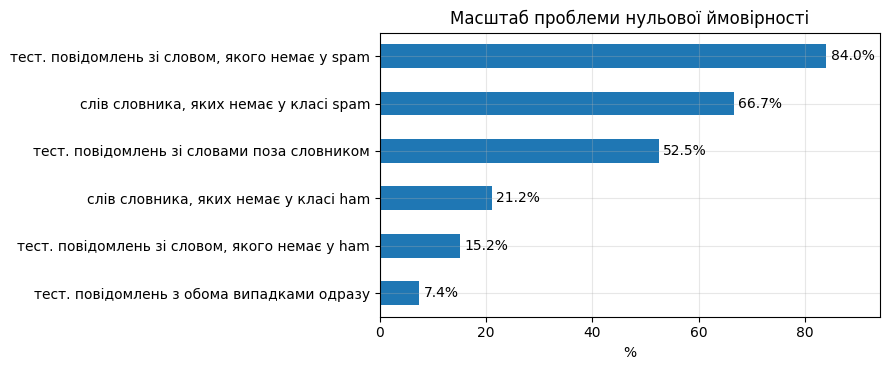

In [11]:
Bin = (A_test > 0).astype(int)
zero_spam, zero_ham = nb0.counts_[1] == 0, nb0.counts_[0] == 0          # слова словника, яких немає в класі
has_zero_spam = Bin.dot(zero_spam.astype(int)) > 0                      # повідомлення містить слово, якого немає у spam
has_zero_ham = Bin.dot(zero_ham.astype(int)) > 0
has_oov = np.array([any(w not in vectorizer.vocabulary_ for w in analyzer(t)) for t in X_test])

scale = pd.Series({
    "слів словника, яких немає у класі spam":              zero_spam.mean(),
    "слів словника, яких немає у класі ham":               zero_ham.mean(),
    "тест. повідомлень зі словом, якого немає у spam":     has_zero_spam.mean(),
    "тест. повідомлень зі словом, якого немає у ham":      has_zero_ham.mean(),
    "тест. повідомлень з обома випадками одразу":          (has_zero_spam & has_zero_ham).mean(),
    "тест. повідомлень зі словами поза словником":         has_oov.mean(),
})
ax = (scale * 100).sort_values().plot.barh(figsize=(9, 3.8), color="tab:blue")
ax.set_xlabel("%"); ax.set_title("Масштаб проблеми нульової ймовірності"); ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.margins(x=0.12); plt.tight_layout(); plt.show()

**Висновок.** Проблема масштабна: 66,7% слів словника ніколи не зустрічались у спамі, а 21,2% — у ham. Через це 84,0% тестових повідомлень містять слово, якого немає у класі spam (без згладжування їхня ймовірність бути спамом дорівнює нулю), 15,2% — слово, якого немає у ham, а для 7,4% нульові ймовірності виникають в обох класах одразу. Крім того, 52,5% тестових повідомлень містять слова поза навчальним словником: вони просто ігноруються, але показують, що «невидані» слова — норма, а не виняток.

### 6.3. Класифікатор без згладжування
Порівнюємо `alpha=0` та `alpha=1` на тестовій вибірці. «Невизначені» — повідомлення, для яких нульову ймовірність мають обидва класи (прогноз неможливий).

In [12]:
forced_ham = np.isinf(s0[:, 1]) & np.isfinite(s0[:, 0])    # нульова ймовірність лише у spam → автоматично ham
res_zero = pd.DataFrame({
    "alpha=0 (без згладжування)": {**metrics(y_test, p0), "невизначених": nb0.undecided(A_test).mean(), "примусово ham": forced_ham.mean()},
    "alpha=1 (Лаплас)":           {**metrics(y_test, p1), "невизначених": nb1.undecided(A_test).mean(), "примусово ham": 0.0},
}).T
res_zero.round(4)

,accuracy,precision,recall,f1,невизначених,примусово ham
alpha=0 (без згладжування),0.9449,0.9405,0.6031,0.7349,0.0745,0.766
alpha=1 (Лаплас),0.9865,0.9756,0.9160,0.9449,0.0000,0.000


**Висновок.** Без згладжування фільтр працює значно гірше: F1 падає з 0,945 до 0,735, а recall — з 0,916 до 0,603, тобто пропускається майже 40% спаму. Для 76,6% тестових повідомлень нульову ймовірність має лише клас spam, тому їх автоматично відносять до ham; ще для 7,5% нуль в обох класах, і прогноз взагалі неможливий. Accuracy (0,945) при цьому виглядає прийнятною, але це оманлива оцінка: більшість повідомлень — ham, і більшість із них автоматично потрапляє до цього класу.

### 6.4. Згладжування Лапласа: вплив параметра alpha
Перебираємо `alpha` від майже нуля (`1e-10`, щоб уникнути `log(0)`) до 20. Оцінка — 5-кратна стратифікована крос-валідація на навчальній вибірці (тестова вибірка не використовується). Оптимальний `alpha` обираємо за F1 для класу spam, бо accuracy на незбалансованих даних дає завищену оцінку.

,accuracy,precision,recall,f1
alpha,,,,
1.000000e-10,0.9799,0.9492,0.8889,0.9178
1.000000e-03,0.9836,0.9491,0.9195,0.9338
1.000000e-02,0.9833,0.9435,0.9233,0.9331
1.000000e-01,0.9852,0.9516,0.9310,0.9409
3.000000e-01,0.9845,0.9508,0.9252,0.9377
5.000000e-01,0.9845,0.9561,0.9195,0.9374
1.000000e+00,0.9840,0.9672,0.9042,0.9345
2.000000e+00,0.9799,0.9804,0.8582,0.9152
5.000000e+00,0.9657,0.9950,0.7319,0.8428


Оптимальний alpha за F1: 0.1


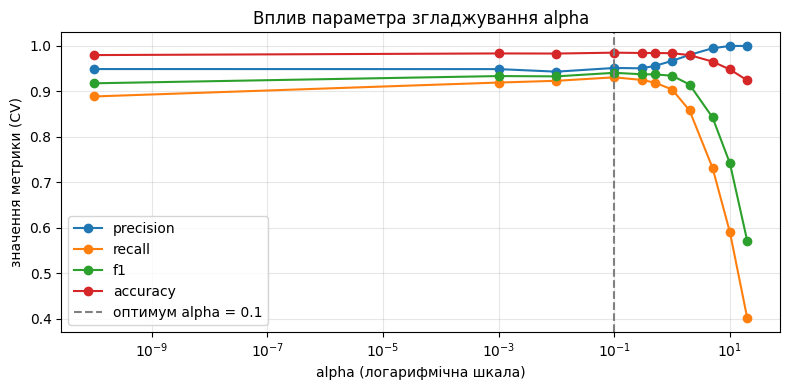

In [13]:
alphas = [1e-10, 1e-3, 1e-2, 0.1, 0.3, 0.5, 1, 2, 5, 10, 20]
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for a in alphas:
    pipe = Pipeline([("vec", CountVectorizer()), ("nb", MultinomialNB(alpha=a))])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    rows.append({"alpha": a, **{m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]}})
res_alpha = pd.DataFrame(rows).set_index("alpha")
best_alpha = res_alpha["f1"].idxmax()
display(res_alpha.round(4))
print("Оптимальний alpha за F1:", best_alpha)

ax = res_alpha[["precision", "recall", "f1", "accuracy"]].plot(marker="o", figsize=(8, 4), logx=True)
ax.axvline(best_alpha, color="gray", ls="--", label=f"оптимум alpha = {best_alpha}")
ax.set_xlabel("alpha (логарифмічна шкала)"); ax.set_ylabel("значення метрики (CV)")
ax.set_title("Вплив параметра згладжування alpha"); ax.legend(); plt.tight_layout(); plt.show()

**Висновок.** Навіть найменше ненульове `alpha = 1e-10` (CV F1 ≈ 0,918) значно краще за чисте `alpha = 0` (на тесті F1 = 0,735): скінченний, хоч і дуже малий, штраф уже дозволяє порівняти класи. Проте такий штраф (log ≈ −32…−34 для слова, якого не було в класі, проти ≈ 1,6 для типового інформативного слова) домінує над рештою слів, тому якість ще нижча за оптимальну. З ростом `alpha` якість досягає максимуму при `alpha = 0,1` (CV F1 ≈ 0,941); далі precision продовжує зростати, а recall різко падає (≈ 0,93 → 0,40 при `alpha = 20`): надто сильне згладжування «розмиває» різницю між класами, і фільтр пропускає спам. Область `alpha` ≈ 0,1–1 дає практично однакову якість.

### 6.5. Вплив розміру навчальної вибірки
Нульові ймовірності виникають тим частіше, чим менше навчальних даних. Порівнюємо `alpha=0`, `alpha=1` та оптимальний `alpha` на навчальних підвибірках різного розміру (для кожного розміру — усереднення за 5 випадкових підвибірок).

модель,alpha=0,alpha=1,alpha=0.1 (оптимум)
n,,,
50,0.1454,0.5367,0.6725
100,0.2160,0.6994,0.7803
200,0.2915,0.7852,0.8445
500,0.3906,0.8616,0.8855
1000,0.5023,0.8981,0.9159
2000,0.6368,0.9218,0.9318
4135,0.7349,0.9449,0.9462


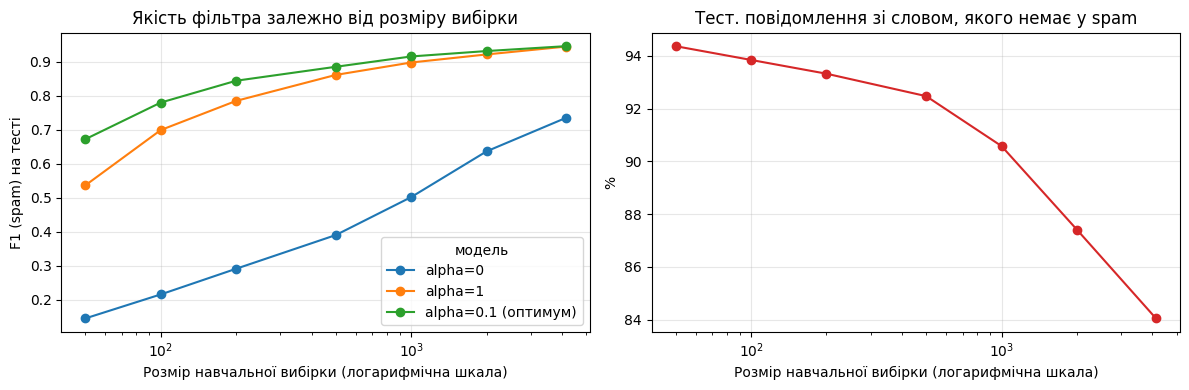

In [14]:
sizes = [50, 100, 200, 500, 1000, 2000, len(X_train)]
models = {"alpha=0": 0, "alpha=1": 1, f"alpha={best_alpha} (оптимум)": best_alpha}
rows_f1, rows_zero = [], []

for n in sizes:
    for seed in ([0] if n == len(X_train) else range(5)):
        if n < len(X_train):
            Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=n, stratify=y_train, random_state=seed)
        else:
            Xs, ys = X_train, y_train
        vec = CountVectorizer().fit(Xs)
        As, At = vec.transform(Xs), vec.transform(X_test)
        for name, a in models.items():
            m = NaiveBayesManual(a).fit(As, ys.values)
            rows_f1.append({"n": n, "модель": name, "f1": f1_score(y_test, m.predict(At), zero_division=0)})
        zs = (np.asarray(As[ys.values == 1].sum(axis=0)).ravel() == 0).astype(int)
        rows_zero.append({"n": n, "частка": ((At > 0).astype(int).dot(zs) > 0).mean()})

f1_by_size = pd.DataFrame(rows_f1).groupby(["n", "модель"])["f1"].mean().unstack()[list(models)]
zero_by_size = pd.DataFrame(rows_zero).groupby("n")["частка"].mean()
display(f1_by_size.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
f1_by_size.plot(marker="o", logx=True, ax=ax[0])
ax[0].set_xlabel("Розмір навчальної вибірки (логарифмічна шкала)"); ax[0].set_ylabel("F1 (spam) на тесті")
ax[0].set_title("Якість фільтра залежно від розміру вибірки")
(zero_by_size * 100).plot(marker="o", logx=True, color="tab:red", ax=ax[1])
ax[1].set_xlabel("Розмір навчальної вибірки (логарифмічна шкала)"); ax[1].set_ylabel("%")
ax[1].set_title("Тест. повідомлення зі словом, якого немає у spam")
plt.tight_layout(); plt.show()

**Висновок.** Чим менша навчальна вибірка, тим болючіша проблема: при 50 прикладах F1 без згладжування лише 0,145 проти 0,537 для `alpha = 1` і 0,673 для `alpha = 0,1`; на повній вибірці (4 135) — 0,735, 0,945 та 0,946 відповідно. Різниця між `alpha = 1` і оптимальним `alpha` з ростом вибірки зменшується майже до нуля. Водночас навіть на повній вибірці 84% тестових повідомлень містять слово, якого немає у класі spam (проти 94% при 50 прикладах): більше даних зменшують проблему, але не усувають її, тому згладжування потрібне завжди.

## 7. Фінальний фільтр та оцінка якості
Фільтр з оптимальним `alpha` навчається на всій навчальній вибірці й оцінюється на тестовій, яку модель не бачила. Також дивимось, які слова модель вважає найбільш «спамовими» та «звичайними», і які спам-повідомлення вона пропускає.

,accuracy,precision,recall,f1
alpha=0 (без згладжування),0.9449,0.9405,0.6031,0.7349
alpha=1 (Лаплас),0.9865,0.9756,0.9160,0.9449
alpha=0.1 (оптимум),0.9865,0.9535,0.9389,0.9462


ROC-AUC фінального фільтра: 0.9875

              precision    recall  f1-score   support

         ham     0.9912    0.9934    0.9923       903
        spam     0.9535    0.9389    0.9462       131

    accuracy                         0.9865      1034
   macro avg     0.9723    0.9661    0.9692      1034
weighted avg     0.9864    0.9865    0.9864      1034



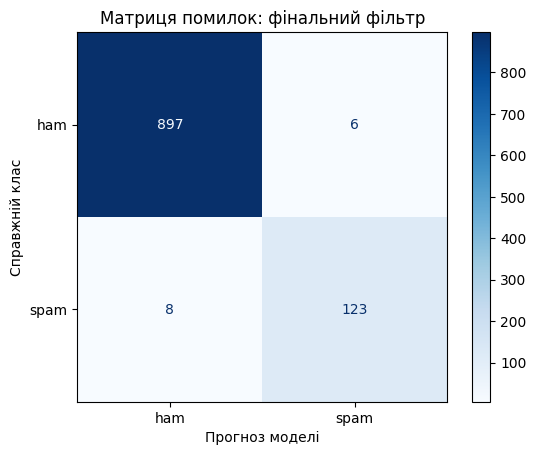

In [15]:
final = Pipeline([("vec", CountVectorizer()), ("nb", MultinomialNB(alpha=best_alpha))]).fit(X_train, y_train)
final_pred = final.predict(X_test)
final_proba = final.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "alpha=0 (без згладжування)": metrics(y_test, p0),
    "alpha=1 (Лаплас)":           metrics(y_test, p1),
    f"alpha={best_alpha} (оптимум)": metrics(y_test, final_pred),
}).T
display(comparison.round(4))
print(f"ROC-AUC фінального фільтра: {roc_auc_score(y_test, final_proba):.4f}\n")
print(classification_report(y_test, final_pred, target_names=["ham", "spam"], digits=4))

disp = ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=["ham", "spam"], cmap="Blues", values_format="d")
disp.ax_.grid(False); disp.ax_.set_title("Матриця помилок: фінальний фільтр")
disp.ax_.set(xlabel="Прогноз моделі", ylabel="Справжній клас")
plt.show()

**Висновок.** Фінальний фільтр (`alpha = 0,1`) на тесті має accuracy 0,987, precision 0,954, recall 0,939, F1 0,946 та ROC-AUC 0,988. Порівняно з `alpha = 1` він виявляє більше спаму (пропущено 8 повідомлень замість 11) ціною трохи більшої кількості хибних тривог (6 замість 3); загальний F1 майже однаковий (0,946 і 0,945), тож різниця між ними в межах похибки — у тесті лише 131 спам-повідомлення. Принципова різниця — з `alpha = 0` (F1 0,735).

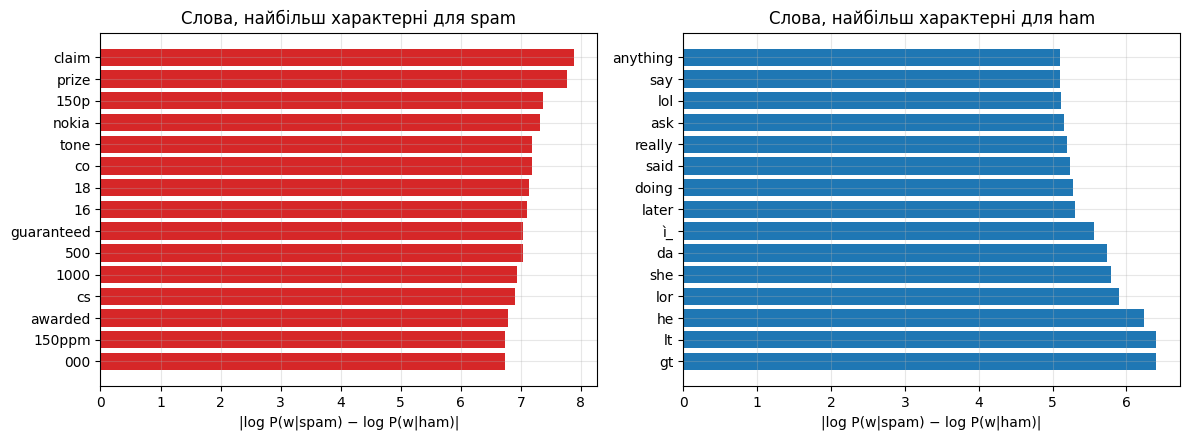

Пропущено спам-повідомлень: 8 із 131. Приклади:
 • Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Callså£1/minMob…
 • Missed call alert. These numbers called but left no message. 07008009200
 • Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XX…
 • In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B…


In [16]:
nb_final, vec_final = final["nb"], final["vec"]
words = np.array(vec_final.get_feature_names_out())
log_ratio = nb_final.feature_log_prob_[1] - nb_final.feature_log_prob_[0]      # log P(w|spam) / P(w|ham)
frequent = nb_final.feature_count_.sum(axis=0) >= 10                           # лише слова, що зустрілись ≥ 10 разів
order = np.argsort(np.where(frequent, log_ratio, np.nan))
order = order[~np.isnan(np.where(frequent, log_ratio, np.nan)[order])]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
top_spam, top_ham = order[::-1][:15][::-1], order[:15]
ax[0].barh(words[top_spam], log_ratio[top_spam], color="tab:red"); ax[0].set_title("Слова, найбільш характерні для spam")
ax[1].barh(words[top_ham], -log_ratio[top_ham], color="tab:blue"); ax[1].set_title("Слова, найбільш характерні для ham")
for a in ax: a.set_xlabel("|log P(w|spam) − log P(w|ham)|")
plt.tight_layout(); plt.show()

missed = X_test[(y_test.values == 1) & (final_pred == 0)]
print(f"Пропущено спам-повідомлень: {len(missed)} із {int(y_test.sum())}. Приклади:")
for t in missed.head(4): print(" •", t[:140] + ("…" if len(t) > 140 else ""))

**Висновок.** Найбільш «спамові» слова — `claim`, `prize`, `150p`, `nokia`, `tone`, `guaranteed`, `awarded`: типова лексика призів, платних послуг і цін. Найбільш «звичайні» — повсякденні слова (`anything`, `say`, `lol`, `ask`, `really`, `later`); слова `gt` і `lt` — залишки HTML-розмітки (`&lt;#&gt;`) у звичайних SMS. Пропущені 8 спам-повідомлень — переважно нетипові тексти з мінімумом характерних слів (особисте «запрошення», «Missed call alert», вікторина).

## 8. Перевірка фільтра на нових повідомленнях
Фільтр застосовується до повідомлень, яких немає в датасеті. В останньому містяться слова, відсутні у словнику (ці слова фільтр просто ігнорує).

In [17]:
new_messages = [
    "Congratulations! You have won a free prize. Call 09061701461 now to claim your reward",
    "URGENT! Your bank account is suspended. Reply with your PIN to restore access",
    "Free entry to win a brand new phone, text WIN to 80082",
    "Hey, are we still meeting for lunch tomorrow?",
    "Can you send me the notes from today's lecture please",
    "Running late, will be there in 10 minutes",
    "Exclusive airdrop: claim your blockchain tokens now",
]
p_spam = final.predict_proba(pd.Series(new_messages))[:, 1]
out = pd.DataFrame({
    "повідомлення": new_messages,
    "P(spam)": p_spam,
    "прогноз": np.where(p_spam > 0.5, "spam", "ham"),
    "слів поза словником": [sum(w not in vec_final.vocabulary_ for w in analyzer(t)) for t in new_messages],
})
out.style.format({"P(spam)": "{:.4f}"}).set_properties(subset=["повідомлення"], **{"text-align": "left"})

,повідомлення,P(spam),прогноз,слів поза словником
0,Congratulations! You have won a free prize. Call 09061701461 now to claim your reward,1.0000,spam,1
1,URGENT! Your bank account is suspended. Reply with your PIN to restore access,1.0000,spam,2
2,"Free entry to win a brand new phone, text WIN to 80082",1.0000,spam,0
3,"Hey, are we still meeting for lunch tomorrow?",0.0000,ham,0
4,Can you send me the notes from today's lecture please,0.0007,ham,0
5,"Running late, will be there in 10 minutes",0.0041,ham,0
6,Exclusive airdrop: claim your blockchain tokens now,0.9994,spam,4


**Висновок.** Фільтр правильно класифікує всі нові повідомлення: три типові спам-повідомлення мають P(spam) ≈ 1, три звичайні — P(spam) ≤ 0,004. В останньому повідомленні чотири слова поза словником (`exclusive`, `airdrop`, `blockchain`, `tokens`) фільтр ігнорує, але повідомлення все одно визнано спамом (P ≈ 0,999) за рештою слів, зокрема `claim`.

## 9. Загальні висновки
1. Створено спам-фільтр на основі наївного байєсівського класифікатора (власна реалізація та `MultinomialNB`, результати збігаються) на датасеті SMS Spam Collection. Фінальний фільтр має **accuracy = 0,987**, **F1 для спаму = 0,946**, **ROC-AUC = 0,988**.
2. **Проблема нульової ймовірності.** Якщо слово не зустрілось у навчальних повідомленнях класу, то $P(w|c)=0$, і весь добуток для цього класу обнуляється незалежно від решти слів. На цих даних це стосується 84% тестових повідомлень; без згладжування F1 падає до 0,735 (recall 0,603), а ≈ 7,5% повідомлень узагалі неможливо класифікувати, бо нуль в обох класах.
3. **Розв'язання — згладжування Лапласа:** до всіх лічильників слів додається `alpha`, тож жодна ймовірність не дорівнює нулю. Оптимум знайдено крос-валідацією (`alpha = 0,1`; діапазон 0,1–1 дає практично однаковий результат). Надто великі `alpha` шкодять: recall різко падає, бо різниця між класами «розмивається».
4. **Вплив розміру вибірки:** чим менше навчальних даних, тим сильніше проблема та вплив `alpha` (при 50 прикладах F1: 0,145 без згладжування проти 0,537 з Лапласом). Навіть на повній вибірці проблема не зникає.
5. **Практичні висновки.** При дисбалансі класів accuracy оманлива (тривіальний фільтр має 0,874), тому фільтр слід оцінювати за precision, recall та F1 для спаму. Слова поза словником фільтр ігнорує.
6. **Обмеження.** Модель «мішок слів» не враховує порядок слів і контекст, а припущення про незалежність слів наближене. У тестовій вибірці лише 131 спам-повідомлення, тому оцінки recall мають помітну похибку; фільтр навчено на англомовних SMS одного джерела, і на інших даних якість може бути іншою.